# Lab 1: Introduction to Qiskit and Single-Qubit Gates

## 1. Setup and Installation

In [ ]:
%pip install qiskit qiskit-aer matplotlib

## 2. Importing Libraries and Checking Versions

In [ ]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting

In [ ]:
print(qiskit.__version__)

2.5.1


In [ ]:
Aer.backends()

[AerSimulator('aer_simulator'),
 AerSimulator('aer_simulator_statevector'),
 AerSimulator('aer_simulator_density_matrix'),
 AerSimulator('aer_simulator_stabilizer'),
 AerSimulator('aer_simulator_matrix_product_state'),
 AerSimulator('aer_simulator_extended_stabilizer'),
 AerSimulator('aer_simulator_unitary'),
 AerSimulator('aer_simulator_superop'),
 QasmSimulator('qasm_simulator'),
 StatevectorSimulator('statevector_simulator'),
 UnitarySimulator('unitary_simulator')]

## 3. Building Your First Quantum Circuit

In [ ]:
from qiskit import ClassicalRegister, QuantumRegister, QuantumCircuit

In [ ]:
cr = ClassicalRegister(1,"cr")
qr = QuantumRegister(1,"qr")
qc = QuantumCircuit(qr,cr)

In [ ]:
!pip install pylatexenc

In [ ]:
!pip install -q pylatexenc

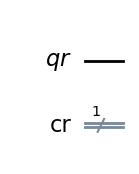

In [ ]:
from qiskit import QuantumCircuit

qc.draw(output="mpl")

#  The Pauli-X Gate (The Quantum NOT Gate)
## 3.1. Simulating the Statevector

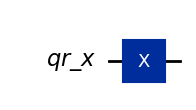

In [ ]:
# Pauli-X gate on |0> qubit
qr_x = QuantumRegister(1, 'qr_x')
cr_x = ClassicalRegister(1, 'cr_x')
qc_x = QuantumCircuit(qr_x)
# apply X-gate to the 0th qubit
qc_x.x(qr_x[0])
# qc.save_statevector()
# qc.save_unitary()
qc_x.draw(output='mpl')

Result after implementing x-gate: Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


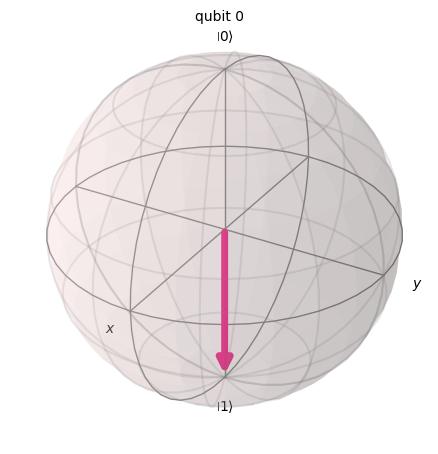

In [ ]:
backend = Aer.get_backend('statevector_simulator')
transpiled_qc_x = transpile(qc_x, backend)
result = backend.run(transpiled_qc_x).result().get_statevector(qc_x, decimals=3)

print("Result after implementing x-gate:",result)
plot_bloch_multivector(result)

## 3.2. Simulating the Unitary Matrix

In [ ]:
backend = Aer.get_backend('unitary_simulator')
result = backend.run(transpiled_qc_x).result().get_unitary(qc_x, decimals=3)
print("Unitary matrix after implementing x-gate:\n",result)

Unitary matrix after implementing x-gate:
 Operator([[0.+0.j, 1.+0.j],
          [1.+0.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


## 3.3. Simulating Measurement

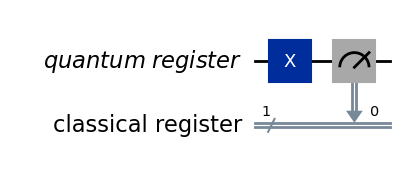

In [ ]:
# measurening the qubit |0> after applying X-gate
cr_x = ClassicalRegister(1, 'classical register')
qr_x = QuantumRegister(1, 'quantum register')
qc_x = QuantumCircuit(qr_x, cr_x)
qc_x.x(qr_x[0])
qc_x.measure(qr_x, cr_x) # measure the qubit
qc_x.draw(output='mpl')

Counts after applying X-gate and measuring the qubit: {'1': 1024}


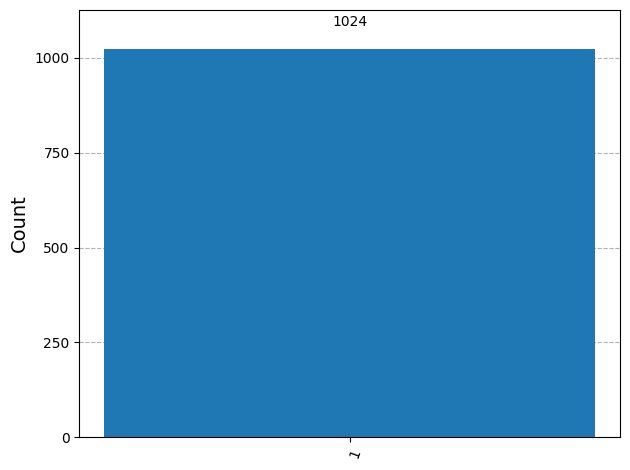

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_x, backend)
result = backend.run(job).result()
counts = result.get_counts(qc_x)
print("Counts after applying X-gate and measuring the qubit:",counts)
plot_histogram(counts)

## 3.4. A Note on Measuring Multi-Qubit Circuits

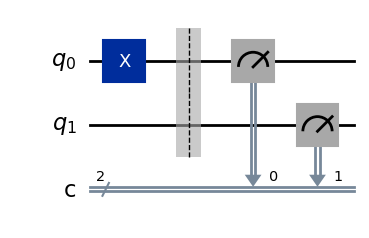

In [ ]:
qc_x = QuantumCircuit(2,2,name='qc_x')
# apply X-gate to the 0th qubit
qc_x.x(0)
# applying barrier
qc_x.barrier()
# qc_x.measure(0,0)
# qc_x.measure(1,1)
# [0,1] is the list of qubits to be measured
# [0,1] is the list of clbits to store the result
qc_x.measure([0,1],[0,1])
qc_x.draw(output='mpl')

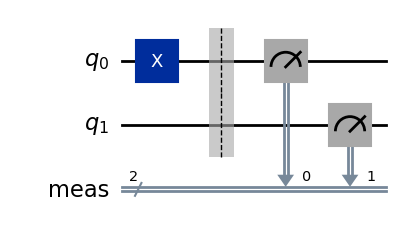

In [ ]:
qc_x = QuantumCircuit(2,name='qc_x')
# apply X-gate to the 0th qubit
qc_x.x(0)
# measuring all qubits
qc_x.measure_all()
qc_x.draw(output='mpl')

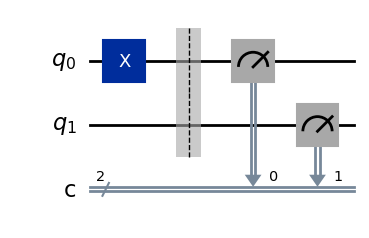

In [ ]:
qc_x = QuantumCircuit(2,2,name='qc_x')
# apply X-gate to the 0th qubit
qc_x.x(0)
# applying barrier
qc_x.barrier()
# qc_x.measure(0,0)
# qc_x.measure(1,1)
# [0,1] is the list of qubits to be measured
# [0,1] is the list of clbits to store the result
qc_x.measure([0,1],[0,1])
qc_x.draw(output='mpl')

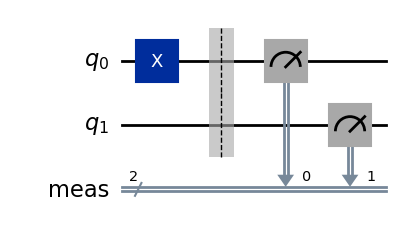

In [ ]:
qc_x = QuantumCircuit(2,name='qc_x')
# apply X-gate to the 0th qubit
qc_x.x(0)
# measuring all qubits
qc_x.measure_all()
qc_x.draw(output='mpl')

# The Pauli-Y Gate
## The Pauli-Y gate is another fundamental single-qubit gate. It performs a 180-degree rotation around the Y-axis of the Bloch Sphere.

## 4.1. Statevector and Unitary Simulation

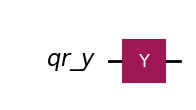

In [ ]:
# Pauli-Y gate on |0> qubit
qr_y = QuantumRegister(1, 'qr_y')
cr_y = ClassicalRegister(1, 'cr_y')
qc_y = QuantumCircuit(qr_y)
# apply Y-gate to the 0th qubit
qc_y.y(qr_y[0])
# qc.save_statevector()
# qc.save_unitary()
qc_y.draw(output='mpl')

Result after implementing y-gate:
 Statevector([0.-0.j, 0.+1.j],
            dims=(2,))


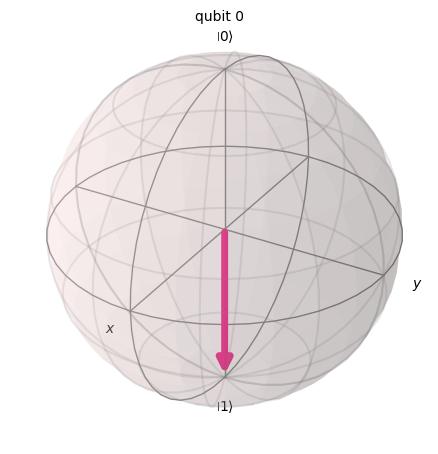

In [ ]:
backend = Aer.get_backend('statevector_simulator')
transpiled_qc_y = transpile(qc_y, backend)
result = backend.run(transpiled_qc_y).result().get_statevector(qc_y, decimals=3)

print("Result after implementing y-gate:\n",result)
plot_bloch_multivector(result)

In [ ]:
backend = Aer.get_backend('unitary_simulator')
result = backend.run(transpiled_qc_y).result().get_unitary(qc_y, decimals=3)
print("Unitary matrix after implementing y-gate:\n",result)

Unitary matrix after implementing y-gate:
 Operator([[0.-0.j, 0.-1.j],
          [0.+1.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


## 4.2. Simulating Measurement

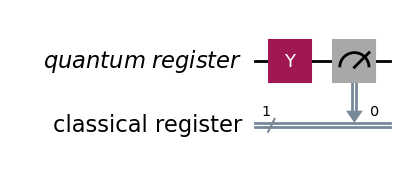

In [ ]:
# Measuring the qubit |0> after applying Y-gate
qr_y = QuantumRegister(1, 'quantum register')
cr_y = ClassicalRegister(1, 'classical register')
qc_y = QuantumCircuit(qr_y, cr_y)
qc_y.y(qr_y[0])
qc_y.measure(qr_y, cr_y) # measure the qubit
qc_y.draw(output='mpl')

Counts after applying Y-gate and measuring the qubit: {'1': 1024}


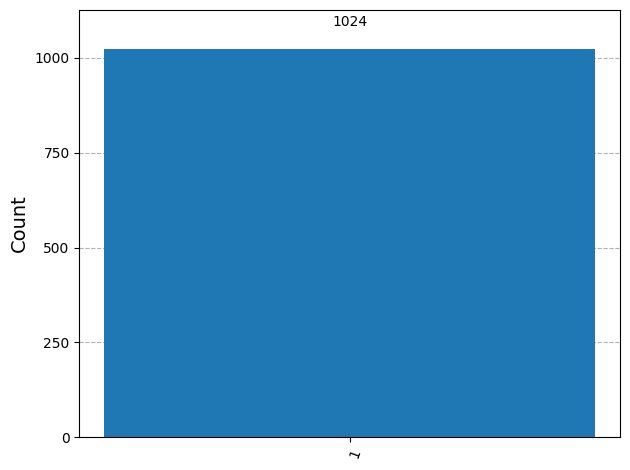

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_y, backend)
result = backend.run(job).result()
counts = result.get_counts(qc_y)
print("Counts after applying Y-gate and measuring the qubit:",counts)
plot_histogram(counts)

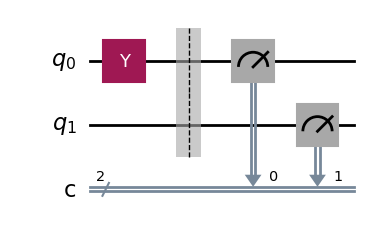

In [ ]:
qc_y = QuantumCircuit(2,2,name='qc_y')
# apply Y-gate to the 0th qubit
qc_y.y(0)
# applying barrier
qc_y.barrier()
# qc_y.measure(0,0)
# qc_y.measure(1,1)
# [0,1] is the list of qubits to be measured
# [0,1] is the list of clbits to store the result
qc_y.measure([0,1],[0,1])
qc_y.draw(output='mpl')

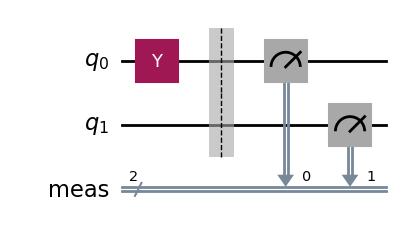

In [ ]:
qc_y = QuantumCircuit(2,name='qc_y')
# apply Y-gate to the 0th qubit
qc_y.y(0)
# measuring all qubits
qc_y.measure_all()
qc_y.draw(output='mpl')

# The Pauli-Z Gate
## 5.1. Statevector Simulation

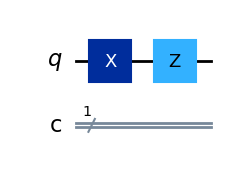

In [ ]:
# Pauli-Y gate on |0> qubit
qc_z = QuantumCircuit(1,1,name='qc_z')
# apply x-gate to the 0th qubit
qc_z.x(0)
# apply z-gate to the 0th qubit
qc_z.z(0)
# qc.save_statevector()
# qc.save_unitary()
qc_z.draw(output='mpl')

Result after implementing z-gate:
 Statevector([ 0.+0.j, -1.-0.j],
            dims=(2,))


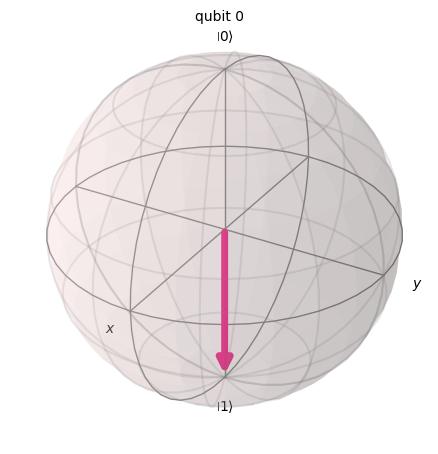

In [ ]:
backend = Aer.get_backend('statevector_simulator')
transpiled_qc_z = transpile(qc_z, backend)
result = backend.run(transpiled_qc_z).result().get_statevector(qc_z, decimals=3)
print("Result after implementing z-gate:\n",result)
plot_bloch_multivector(result)

In [ ]:
backend = Aer.get_backend('unitary_simulator')
result = backend.run(transpiled_qc_z).result().get_unitary(qc_z, decimals=3)
print("Unitary matrix after implementing z-gate:\n",result)

Unitary matrix after implementing z-gate:
 Operator([[ 0.+0.j,  1.+0.j],
          [-1.-0.j,  0.+0.j]],
         input_dims=(2,), output_dims=(2,))


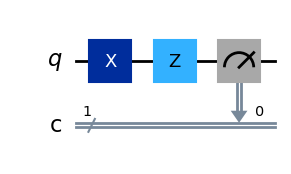

In [ ]:
# Measuring the qubit |0> after applying Y-gate
qc_z = QuantumCircuit(1,1,name='qc_y')
qc_z.x(0)
qc_z.z(0)
qc_z.measure(0,0) # measure the qubit
qc_z.draw(output='mpl')

Counts after applying Y-gate and measuring the qubit: {'1': 1024}


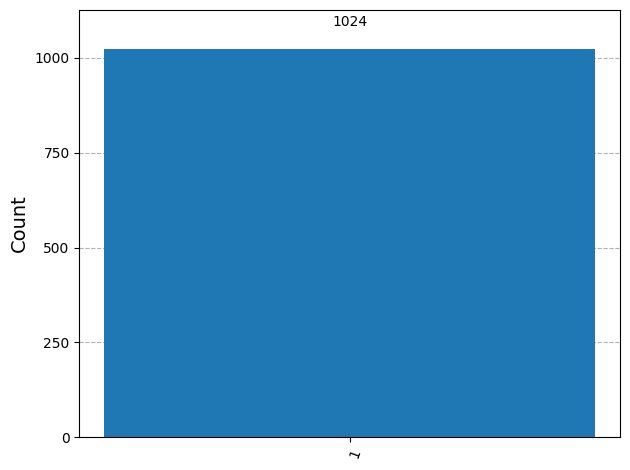

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_z, backend)
result = backend.run(job).result()
counts = result.get_counts(qc_z)
print("Counts after applying Y-gate and measuring the qubit:",counts)
plot_histogram(counts)

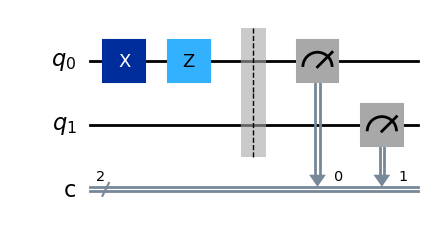

In [ ]:
qc_z = QuantumCircuit(2,2,name='qc_z')
# apply X-gate to the 0th qubit
qc_z.x(0)
# apply Z-gate to the 0th qubit
qc_z.z(0)
# applying barrier
qc_z.barrier()
# qc_z.measure(0,0)
# qc_z.measure(1,1)
# [0,1] is the list of qubits to be measured
# [0,1] is the list of clbits to store the result
qc_z.measure([0,1],[0,1])
qc_z.draw(output='mpl')

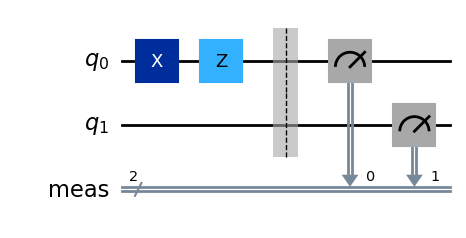

In [ ]:
qc_z = QuantumCircuit(2,name='qc_z')
# apply Z-gate to the 0th qubit
qc_z.x(0)
qc_z.z(0)
# measuring all qubits
qc_z.measure_all()
qc_z.draw(output='mpl')

## 6. The Hadamard Gate

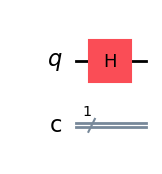

In [ ]:
# H-gate on |0> qubit
qc_h = QuantumCircuit(1,1,name='qc_h')
# apply H-gate to the 0th qubit
qc_h.h(0)
# qc.save_statevector()
# qc.save_unitary()
qc_h.draw(output='mpl')

## 6.1. Statevector Simulation

Result after implementing H-gate:
 Statevector([0.707+0.j, 0.707+0.j],
            dims=(2,))


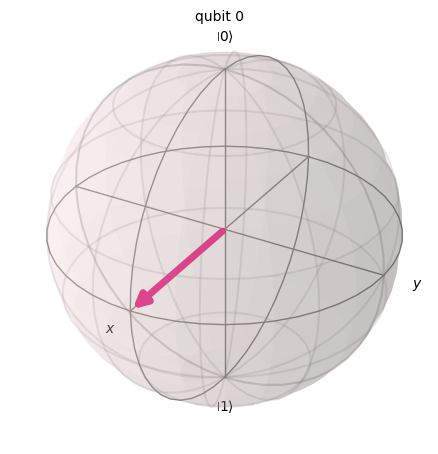

In [ ]:
backend = Aer.get_backend('statevector_simulator')
transpiled_qc_h = transpile(qc_h, backend)
result = backend.run(transpiled_qc_h).result().get_statevector(qc_h, decimals=3)
print("Result after implementing H-gate:\n",result)
plot_bloch_multivector(result)

In [ ]:
backend = Aer.get_backend('unitary_simulator')
result = backend.run(transpiled_qc_h).result().get_unitary(qc_h, decimals=3)
print("Unitary matrix after implementing H-gate:\n",result)

Unitary matrix after implementing H-gate:
 Operator([[ 0.707+0.j,  0.707-0.j],
          [ 0.707+0.j, -0.707+0.j]],
         input_dims=(2,), output_dims=(2,))


## 6.2. Measurement

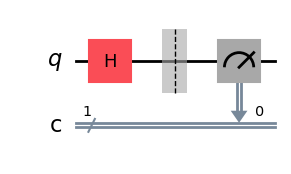

In [ ]:
# Measuring the qubit |0> after applying Y-gate
qc_h = QuantumCircuit(1,1,name='qc_y')
qc_h.h(0)
qc_h.barrier()
qc_h.measure(0,0) # measure the qubit
qc_h.draw(output='mpl')

Counts after applying H-gate and measuring the qubit: {'0': 495, '1': 505}


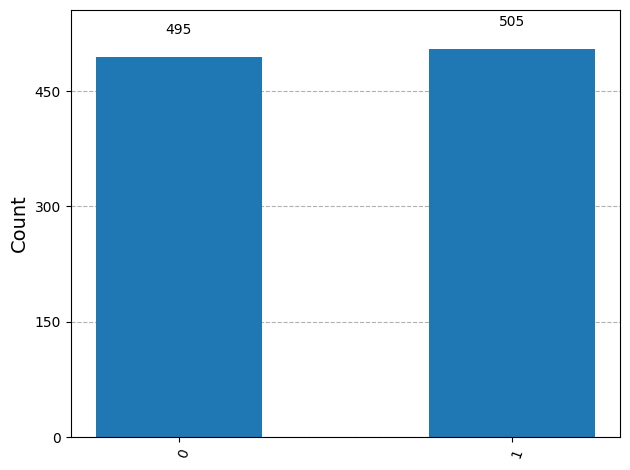

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_h, backend)
result = backend.run(job, shots=1000).result()
counts = result.get_counts(qc_h)
print("Counts after applying H-gate and measuring the qubit:",counts)
plot_histogram(counts)

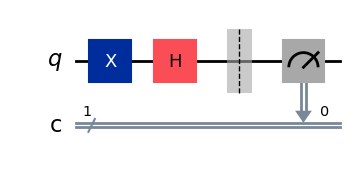

In [ ]:
# Measuring the qubit |0> after applying Y-gate
qc_h = QuantumCircuit(1,1,name='qc_y')
qc_h.x(0)
qc_h.h(0)
qc_h.barrier()
qc_h.measure(0,0) # measure the qubit
qc_h.draw(output='mpl')

Counts after applying X-gate then H-gate and measuring the qubit: {'1': 495, '0': 505}


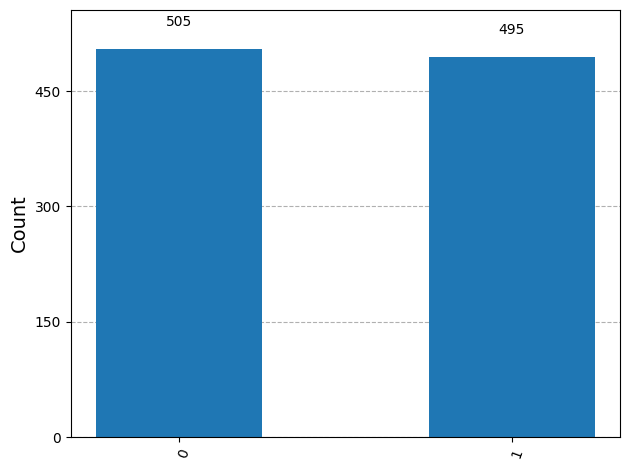

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_h, backend)
result = backend.run(job,shots = 1000).result()
counts = result.get_counts(qc_h)
print("Counts after applying X-gate then H-gate and measuring the qubit:",counts)
plot_histogram(counts)

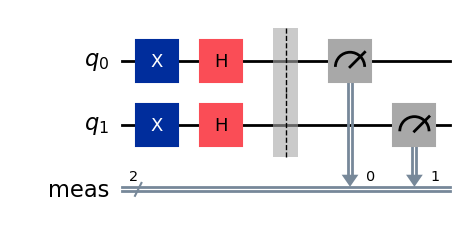

In [ ]:
qc_h = QuantumCircuit(2,name='qc_z')
# apply Z-gate to the 0th qubit
qc_h.x(0)
qc_h.h(0)
qc_h.x(1)
qc_h.h(1)
# measuring all qubits
qc_h.measure_all()
qc_h.draw(output='mpl')

Counts after applying X-gate then H-gate and measuring the qubit: {'01': 253, '11': 249, '00': 269, '10': 229}


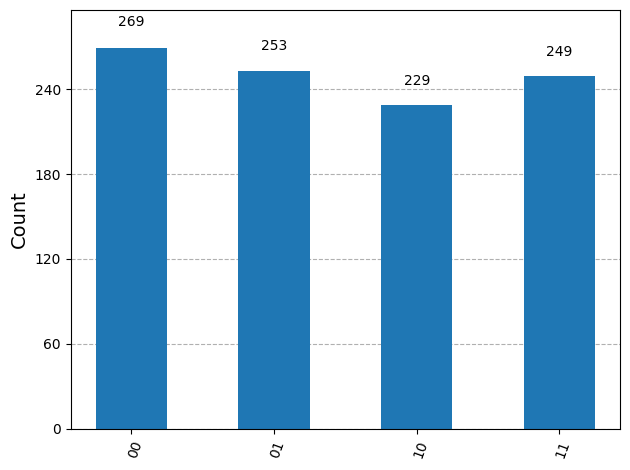

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_h, backend)
result = backend.run(job,shots = 1000).result()
counts = result.get_counts(qc_h)
print("Counts after applying X-gate then H-gate and measuring the qubit:",counts)
plot_histogram(counts)

Result after implementing H-gate:
 Statevector([0.+0.j, 0.-0.j, 0.+0.j, 1.+0.j],
            dims=(2, 2))


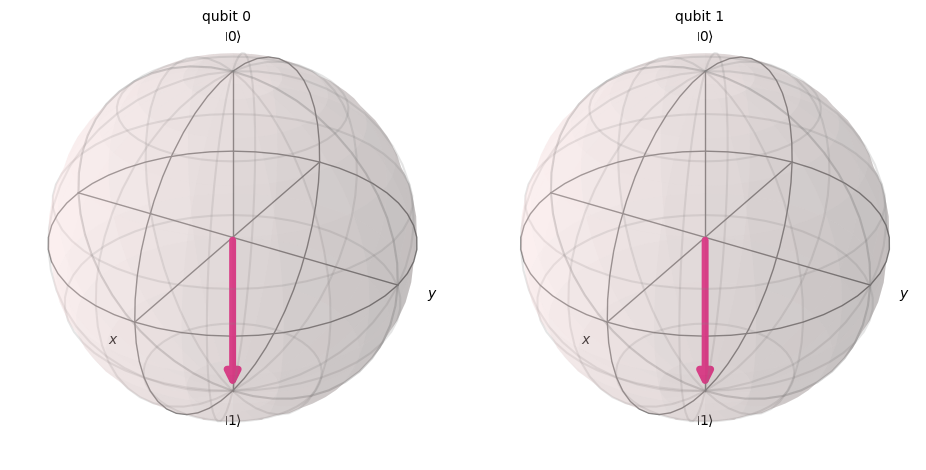

In [ ]:
backend = Aer.get_backend('statevector_simulator')
transpiled_qc_h = transpile(qc_h, backend)
result = backend.run(transpiled_qc_h).result().get_statevector(qc_h, decimals=3)
print("Result after implementing H-gate:\n",result)
plot_bloch_multivector(result)

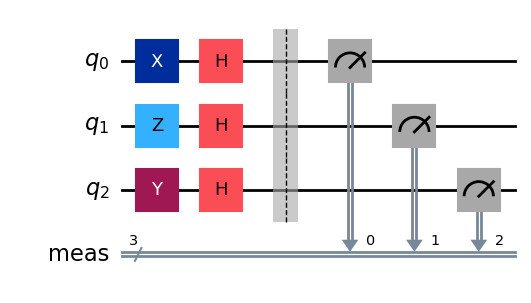

In [ ]:
qc_h = QuantumCircuit(3,name='qc_z')
# apply Z-gate to the 0th qubit
qc_h.x(0)
qc_h.h(0)
qc_h.z(1)
qc_h.h(1)
qc_h.y(2)
qc_h.h(2)
# measuring all qubits
qc_h.measure_all()
qc_h.draw(output='mpl')

Counts after applying X-gate then H-gate and measuring the qubit: {'100': 123, '101': 135, '001': 131, '110': 113, '000': 130, '010': 134, '011': 112, '111': 122}


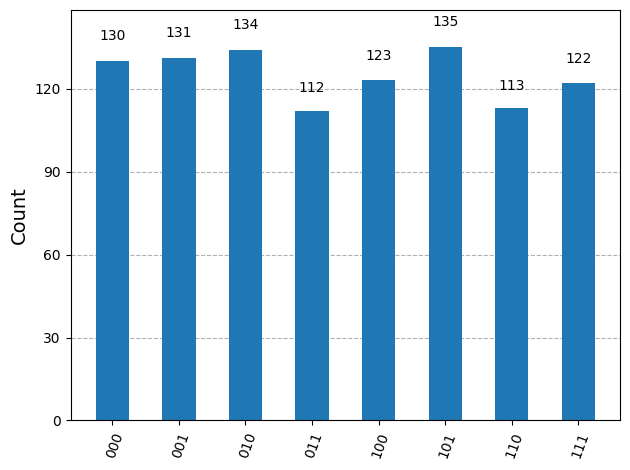

In [ ]:
backend = Aer.get_backend('qasm_simulator')
job = transpile(qc_h, backend)
result = backend.run(job,shots = 1000).result()
counts = result.get_counts(qc_h)
print("Counts after applying X-gate then H-gate and measuring the qubit:",counts)
plot_histogram(counts)

Result after implementing H-gate:
 Statevector([ 0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j, -0.+0.j,  0.+0.j,
             -0.+1.j],
            dims=(2, 2, 2))


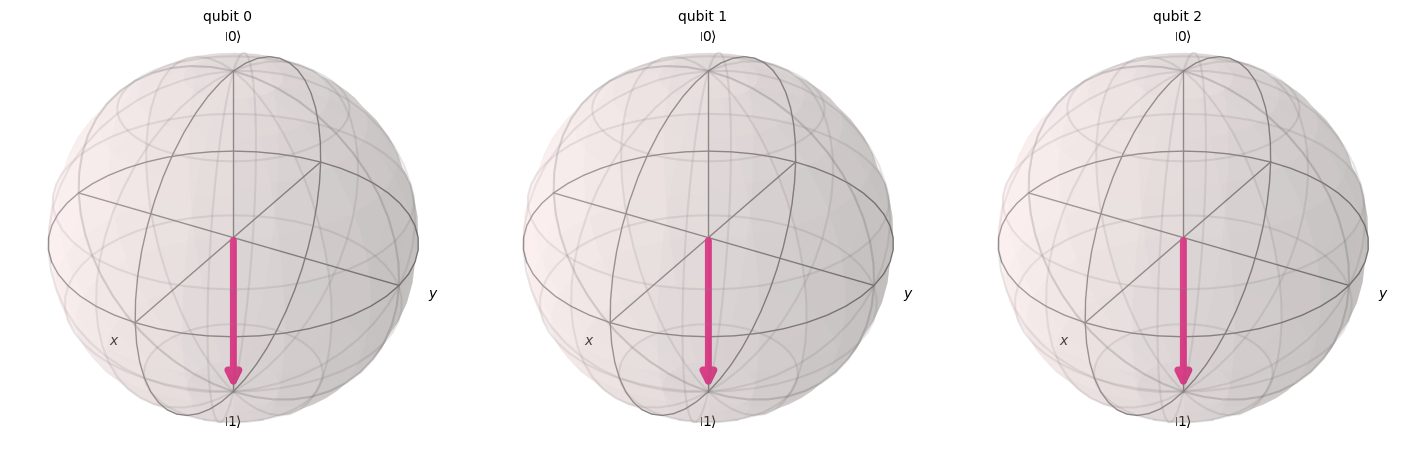

In [ ]:
backend = Aer.get_backend('statevector_simulator')
transpiled_qc_h = transpile(qc_h, backend)
result = backend.run(transpiled_qc_h).result().get_statevector(qc_h, decimals=3)
print("Result after implementing H-gate:\n",result)
plot_bloch_multivector(result)